# EEI-303 – Processamento de Voz e Áudio

## 24202631372 - Matheus Costa Damasceno

---

In [19]:
import scipy.signal as signal
import numpy as np
import scipy
import matplotlib.pyplot as plt
import librosa
from pylab import *
from IPython.display import Audio
from librosa.display import specshow

# Aula 05 - Laboratório 1 - Análise de formas de onda, espectro e espectograma

As atividades deverão ser realizadas no ambiente COLAB ou em Jupyter Notebook e o arquivo, contendo os resultados e as respostas das questões, enviado em formato .ipynb pelo formulário.

## Atividade 1:

Seja $x[n] = \cos(w_0 n + \phi)$. Vamos gerar 100 amostras do sinal $x[n]$ com frequência angular igual a $w_0 = 0.1\pi$ radianos por amostra e fase $0.25\pi$ e ilustrar a sua forma de onda.   






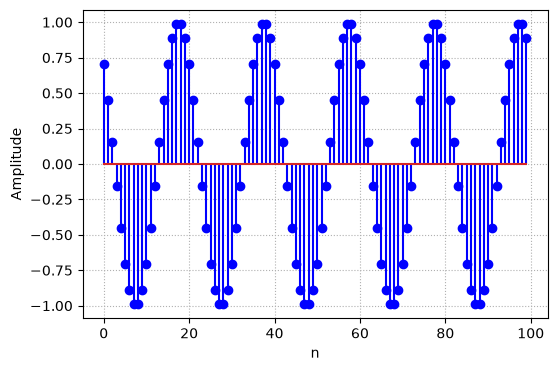

In [20]:
N = 100
n = np.linspace(0,N,N, endpoint=False)

w0 = 0.1*pi
phi = 0.25*pi

x = np.cos(w0*n+phi)

plt.figure(figsize=(6,4))
plt.stem(n , x, linefmt='b-')
plt.grid(True, linestyle=':')
ylabel('Amplitude')
xlabel('n')
plt.show()

## Atividade 2:
Vamos agora calcular e ilustrar o **espectro de amplitude** utilizando a FFT (Fast Fourier Transform).

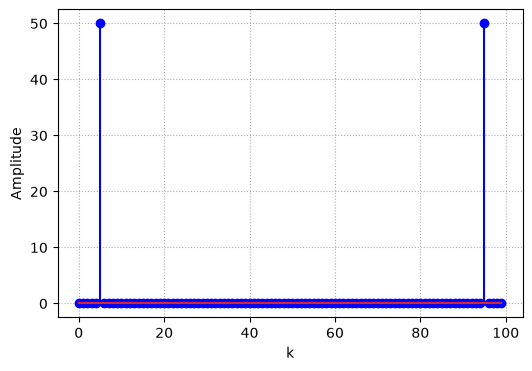

In [21]:
X = np.fft.fft(x)
Xa = abs(X)
plt.figure(figsize=(6,4))
plt.stem(n , Xa, linefmt='b-')
plt.grid(True, linestyle=':')
ylabel('Amplitude')
xlabel('k')
plt.show()

Sabendo que o eixo horizontal (abscissa) corresponde à frequência angular, vamos agora criar um vetor de índices equivalente à frequência angular amostrada.

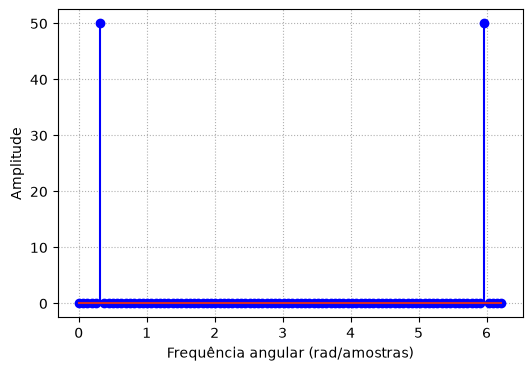

In [22]:
w = n*2*pi/N
plt.figure(figsize=(6,4))
plt.stem(w , Xa, linefmt='b-')
plt.grid(True, linestyle=':')
ylabel('Amplitude')
xlabel('Frequência angular (rad/amostras)')
plt.show()

Ou, ainda, através da sua frequência angular normalizada.

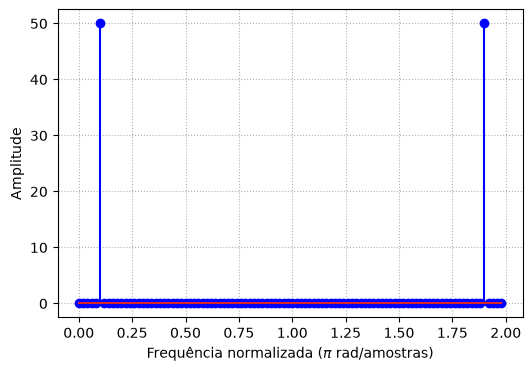

In [23]:
plt.figure(figsize=(6,4))
plt.stem(w/pi , Xa, linefmt='b-')
plt.grid(True, linestyle=':')
ylabel('Amplitude')
xlabel('Frequência normalizada ($\\pi$ rad/amostras)')
plt.show()

## Atividade 3:

Vamos agora ilustrar o **espectro de fase** deste sinal.

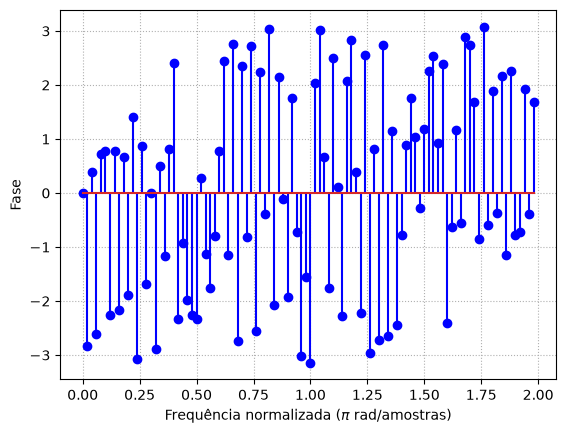

In [24]:
Xp = np.arctan2(imag(X),real(X))
plt.stem(w/pi , Xp, linefmt='b-')
plt.grid(True, linestyle=':')
ylabel('Fase')
xlabel('Frequência normalizada ($\\pi$ rad/amostras)')
plt.show()

O resultado acima é totalmente diferente do que o esperado (esperávamos obter apenas dois impulsos, um de $0.25\pi$ em $0.1\pi$ e outro de $-0.25\pi$ em $1.9\pi$. O que ocorre é que o cálculo da fase é bastante ruidoso, uma vez que é dado pelo arco tangente da razão entre a parte imaginária e a parte real. Uma forma de contornar este problema, é calcular o seu valor apenas para o caso em que a amplitude é significativa, o que pode ser feito definindo um limiar.

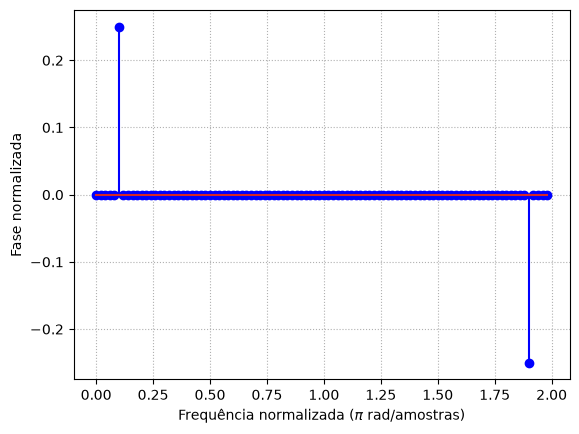

In [25]:
threshold = max(abs(X))/10000

X2 = np.copy(X)
X2[abs(X) < threshold] = 0

X2p = np.arctan2(imag(X2),real(X2))

plt.stem(w/pi , X2p/pi, linefmt='b-')
plt.grid(True, linestyle=':')
ylabel('Fase normalizada')
xlabel('Frequência normalizada ($\\pi$ rad/amostras)')
plt.show()

## Atividade 4:

Como seria possível relacionar o sinal discreto no tempo $x[n]$, considerando que o mesmo foi obtido através de um processo de amostragem de um sinal contínuo no tempo $x[t]$?

Os sinais contínuos no tempo se relacionam com os sinais discretos no tempo através do período de amostragem $T_s$ ou a sua inversa $f_s = \frac{1}{T_s}$, conhecida como frequência de amostragem.

No processo de amostragem, responsável pela conversão de um sinal contínuo $x(t)$ no tempo em um sinal discreto no tempo $x[n]$, estes sinais se relacionam da seguinte maneira:





<center>
<img src="https://drive.google.com/uc?id=1Q9eQPSxpvpiEfzBrR_FTIKUog7nO_2h5"
	width="50%" />
</center>

Assim, estes sinais se relacionam da seguinte maneira:

\begin{align}
    x[n] = x(t = nT_s)
\end{align}

Vamos agora considerar que o sinal $x[n] = \cos(0.1\pi n + 0.25\pi)$ foi obtido através de um processo de amostragem de um sinal $x(t) = \cos(2\pi f t + 0.25\pi)$, com uma frequência igual a $1 kHz$ e frequência de amostragem igual a  $20 kHz$. Observe que, neste caso, tem que ser respeitada a seguinte relação:

$$ 2\pi f t = 0.1 \pi n $$

$$ 2\pi f n T_s = 0.1 \pi n $$

$$ 2\pi \frac{f}{f_s} = 0.1 \pi $$






Vamos agora ilustrar a sua forma de onda, considerando o índice temporal em segundos

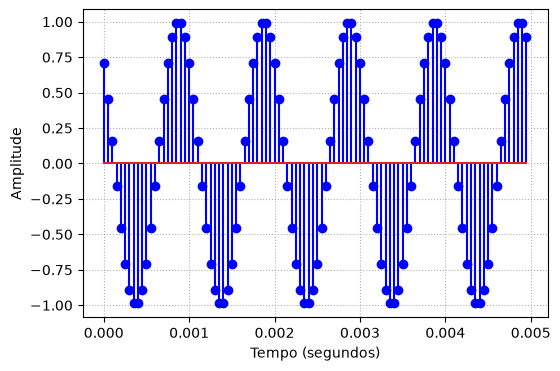

In [26]:
fs = 20000
t  = n/fs

plt.figure(figsize=(6,4))
plt.stem(t , x, linefmt='b-')
plt.grid(True, linestyle=':')
ylabel('Amplitude')
xlabel('Tempo (segundos)')
plt.show()

Já o espectro de amplitude, considerando o eixo das abscissas em termos da frequência em Hz.  

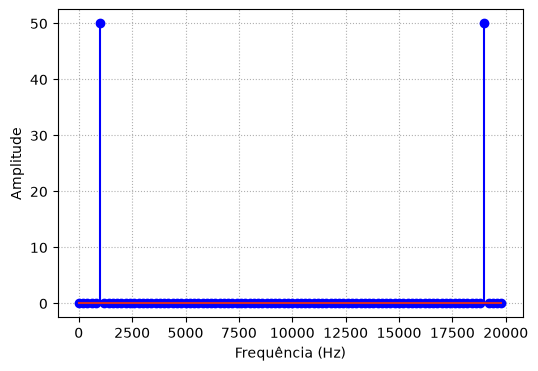

In [27]:
f = n*fs/N
plt.figure(figsize=(6,4))
plt.stem(f , Xa, linefmt='b-')
plt.grid(True, linestyle=':')
ylabel('Amplitude')
xlabel('Frequência (Hz)')
plt.show()

## Atividade 5:

Vamos agora considerar um sinal composto de 3000 amostras onde as 1000 primeiras amostras correspondem a um sinal senoidal de frequência igual 1 kHz, as amostras de número 1000 a 1999 correspondem a um sinal senoidal de frequência igual a 2,5 kHz e as amostras de número 2000 a 2999 correspondem a um sinal senoidal de frequência igual a 5,0 kHz. Considere que o sinal foi amostrado com uma taxa de 22050 kHz.


In [28]:
N = 3000
n = np.linspace(0,N,N, endpoint=False)
fs = 22050
f1 = 1000
f2 = 2500
f3 = 5000

w1 = 2*pi*f1/fs
x1 = np.cos(w1*n)
w2 = 2*pi*f2/fs
x2 = np.cos(w2*n)
w3 = 2*pi*f3/fs
x3 = np.cos(w3*n)

x = np.zeros(N)

x[0:1000] = x1[0:1000]
x[1000:2000] = x2[1000:2000]
x[2000:3000] = x3[2000:3000]

> 1 - ilustre a sua forma de onda

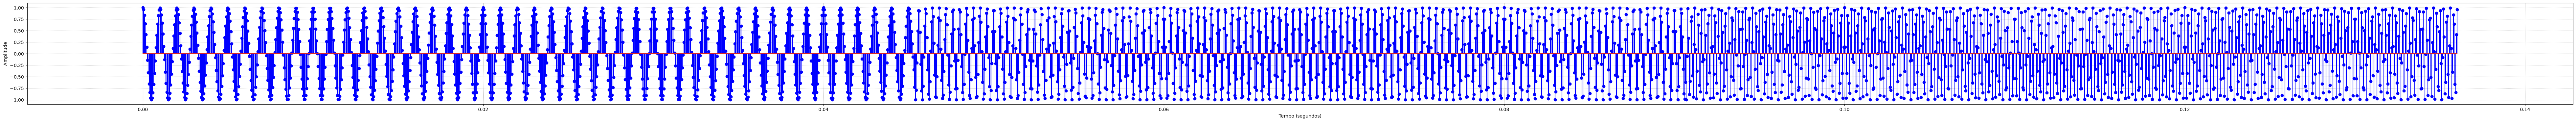

In [29]:
t  = n/fs
plt.figure(figsize=(100,4))
plt.stem(t , x, linefmt='b-')
plt.grid(True, linestyle=':')
ylabel('Amplitude')
xlabel('Tempo (segundos)')
plt.show()

> 2 - ilustre a seu espectro de amplitude



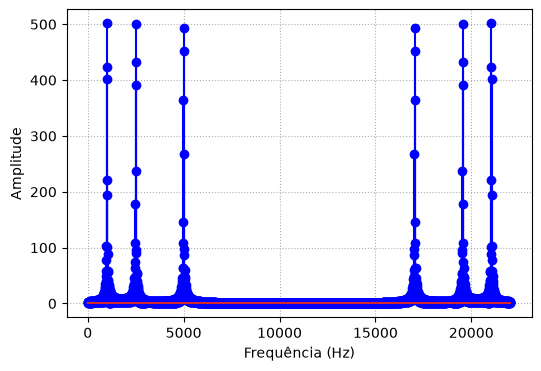

In [30]:
X = np.fft.fft(x)

Xa = abs(X)
f  = n*fs/N

plt.figure(figsize=(6,4))
plt.stem(f , Xa, linefmt='b-')
plt.grid(True, linestyle=':')
ylabel('Amplitude')
xlabel('Frequência (Hz)')
plt.show()

Agora, vamos considerar um sinal diferente, resultante da somatória de 3 sinais senoidais com frequências iguais a 1 kHz, 2,5 kHz e 5,0 kHz. Também amostrado com uma taxa de 22050 Hz.

Ao observar o espectro de amplitude deste sinal, vemos que ele é bastante parecido com o espectro de amplitude do sinal anterior, no qual temos estas 3 componentes de frequência acontecendo em momentos disttintos.

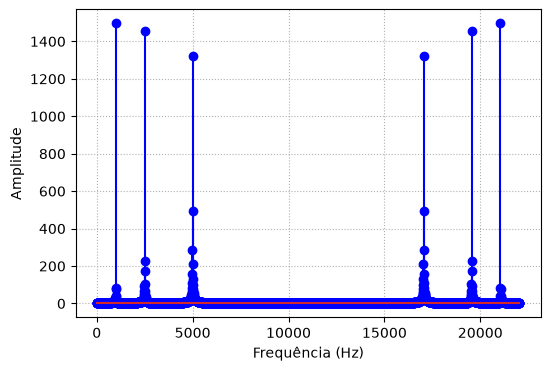

In [31]:
X2 = np.fft.fft(x1+x2+x3)

X2a = abs(X2)
f  = n*fs/N

plt.figure(figsize=(6,4))
plt.stem(f , X2a, linefmt='b-')
plt.grid(True, linestyle=':')
ylabel('Amplitude')
xlabel('Frequência (Hz)')
plt.show()

A forma de onda deste novo sinal é dada pela Figura abaixo:

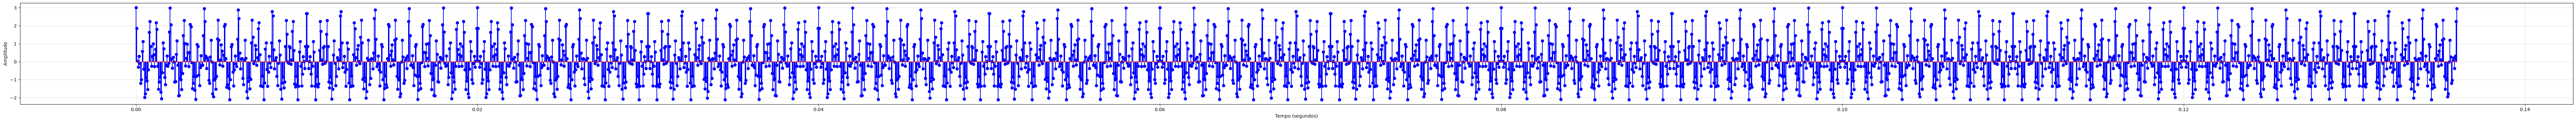

In [32]:
t  = n/fs
plt.figure(figsize=(100,4))
plt.stem(t , x1+x2+x3, linefmt='b-')
plt.grid(True, linestyle=':')
ylabel('Amplitude')
xlabel('Tempo (segundos)')
plt.show()

Observe que através do espectro de frequência é possível ver que o sinal da Atividade 5 é composto de 3 frequências predominantes. No entanto, não temos nenhuma informação a respeito de como essas frequências variam com relação ao tempo. Para isso, é possível utilizar o chamado espectograma, que corresponde a tomarmos a sua transformada de fourier para diferentes intervalos de tempo consecutivos.

Text(0, 0.5, 'Frequency [Hz]')

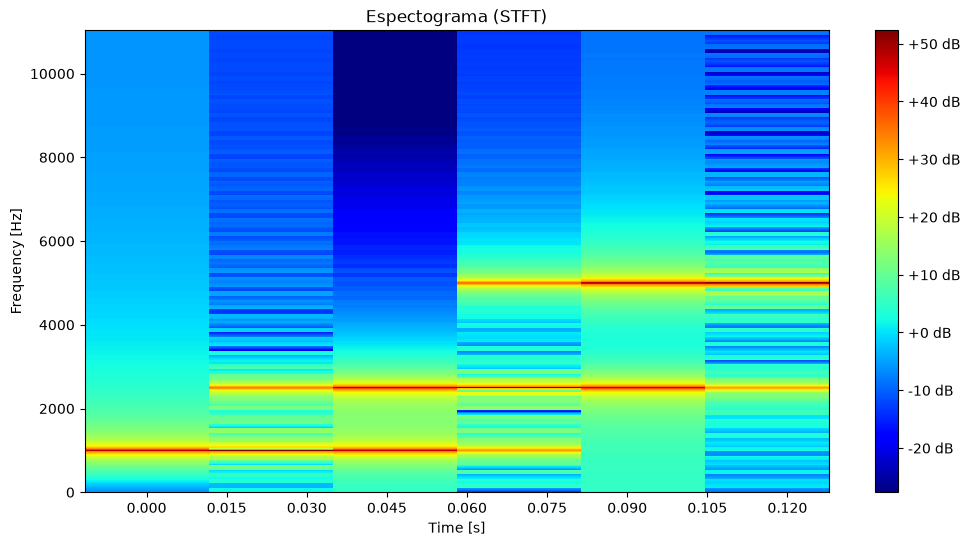

In [33]:
X_stft = np.abs(librosa.stft(x))
plt.figure(figsize=(12,6))
specshow(librosa.amplitude_to_db(X_stft),
         y_axis='linear',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Espectograma (STFT)')
plt.xlabel('Time [s]')
plt.colorbar(format='%+2.0f dB')
plt.ylabel('Frequency [Hz]')

#https://stackoverflow.com/questions/66235936/why-spectrogram-from-librosa-library-have-different-time-duration-of-the-actual

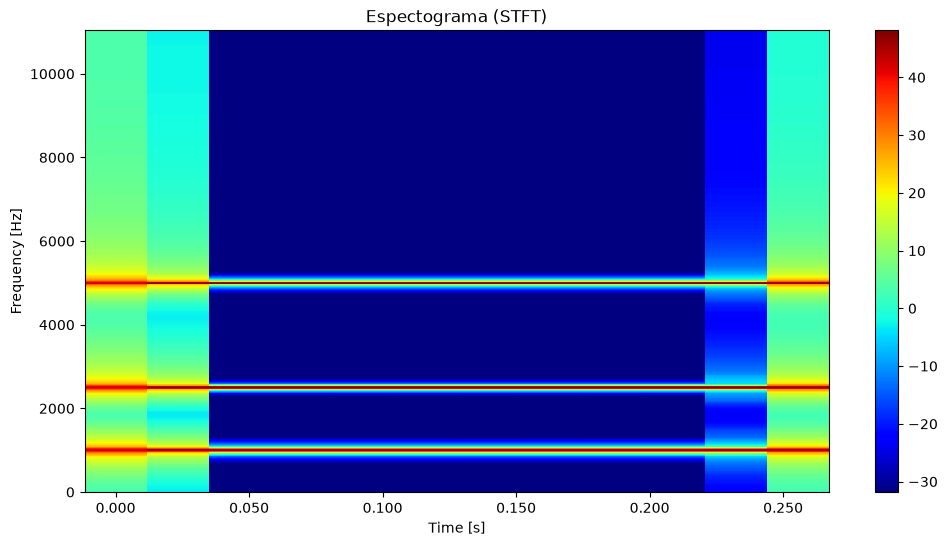

In [34]:
X_stft = np.abs(librosa.stft(x1+x2+x3,n_fft=1024))
plt.figure(figsize=(12,6))
specshow(librosa.amplitude_to_db(X_stft),
         y_axis='linear',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Espectograma (STFT)')
plt.xlabel('Time [s]')
plt.ylabel('Frequency [Hz]')
plt.colorbar()

## Exercícios:

In [35]:
import os, urllib.request

REPO_RAW = "https://raw.githubusercontent.com/Mathcd/2026-3-Processamento-de-Voz-e-Audio/main/2-ExerciciosComputacionais/Audios/"

def caminho_audio(nome):
    """Usa o áudio local se existir; senão baixa do GitHub (ex.: no Colab)."""
    caminho = os.path.join("Audios", nome)
    if not os.path.exists(caminho):
        os.makedirs("Audios", exist_ok=True)
        urllib.request.urlretrieve(REPO_RAW + nome, caminho)
    return caminho

## Exercício 1: Escute o áudio acima e o descreva.

In [36]:
audio_sample, fs = librosa.load(caminho_audio("audio.wav"), sr=48000)

print('Sample rate:', fs)
print('Frames:', audio_sample.shape[0])
print('Duração:', audio_sample.shape[0] / fs)

Sample rate: 48000
Frames: 576000
Duração: 12.0


In [37]:
Audio(data=audio_sample, rate=fs)

O áudio tem duração de 12 segundos, amostrados a 48 kHz e contém 576.000 frames. Ele foi criado a partir da concatenação de 4 trilhas de 3 segundos cada:

- t0=0s a t1=3s: trata-se da voz de uma pessoa falando a vogal "u" de maneira sustentada. Apesar de ser possível escutar e confirmar que o som é consistente com a vogal "u", se fosse um teste "cego", isto é, sem informações prévias a respeito do conteúdo, tal trecho de áudio poderia facilmente ser confundido com algum outro ruído grave e constante, tal como um ventilador ou motor;

- t1=3s a t2=6s: é um violino tocando notas agudas. É possível confundir com outros instrumentos ou até mesmo alguns tipos de apito, mas sim, também é possível ouvir claramente o som do instrumento;

- t2=6s a t3=9s: trata-se de um molho de chaves sendo chacoalhado. Assim como o caso do "u", este também poderia facilmente ser confundido com um sino dos ventos ou algum outro instrumento musical. Também é possível ouvir claramente o áudio e observa-se um som mais agudo, devido ao som produzido pela colisão entre as chaves;

- t3=9s a t4=12s: aqui podemos ouvir os três áudios anteriores tocando simultaneamente. Como eles estão somados, não é possível ouvir com a mesma clareza com que os áudios que estão tocando individualmente, mas ainda assim é possível notar a presença dos três sinais tocando ao mesmo tempo.

## Exercício 2: Ilustre e analize (descreva) a forma de onda do sinal.

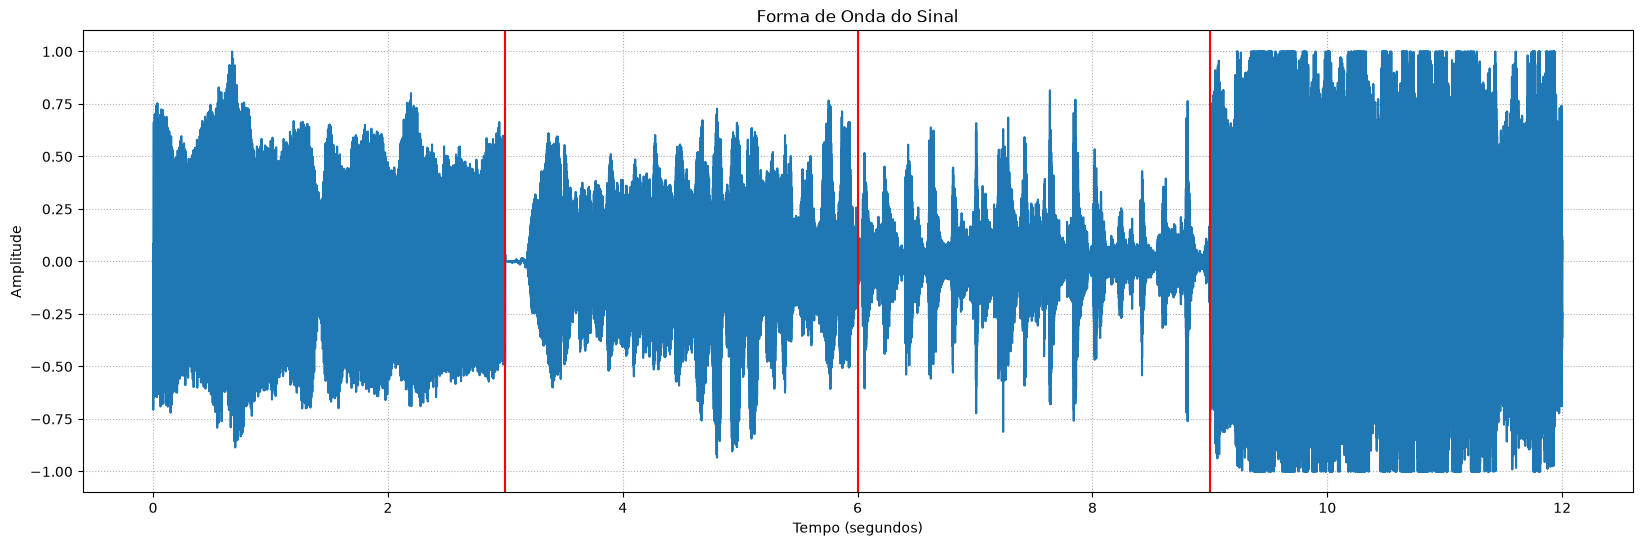

In [38]:
N = len(audio_sample)
n = np.linspace(0,N,N, endpoint=False)
x = np.copy(audio_sample[:N])

t  = n/fs
plt.figure(figsize=(20,6))
plt.plot(t , x)
plt.grid(True, linestyle=':')
ylabel('Amplitude')
xlabel('Tempo (segundos)')
plt.axvline(3, color='red')
plt.axvline(6, color='red')
plt.axvline(9, color='red')
plt.title('Forma de Onda do Sinal')
plt.show()

Ao observar a forma de onda do sinal no domínio do tempo, verifica-se uma descontinuidade clara entre o padrão observado nos instantes de tempo t1=3, t2=6, t3=9, que correspondem justamente aos instantes em que há a transição entre os 4 segmentos do áudio. 

No primeiro segmento, a forma de onda é bem preenchida. Nesta escala de tempo não é possível visualizar os ciclos individuais da onda, apenas a sua envoltória, que é quase constante entre os intervalos [0.50, 0.75] e [-0.75, -0.50].

Já no segundo trecho, observa-se que forma de onda, em média, tem uma amplitude menor, que indica uma quantidade menor de energia. No terceiro, ainda menos. Em ambos a envoltória do sinal varia muito mais ao longo do tempo que no primeiro segmento, especialmente no caso das chaves, pois cada colisão gera um pico de energia, mas de curta duração.

No quarto segmento, que é a soma dos três anteriores sem normalização (por exemplo, multiplicar por 1/3), as amplitudes foram somadas diretamente. Isso faz com que em alguns pontos ela vá além dos valores máximos de amplitude do intervalo suportado pelo sistema, correspondente a [-1, 1], o que causa saturação. Entretanto, apesar de ser simples de observar esse fenômeno na visualização gráfica, tal distorção não é facilmente percebida ouvindo a amostra de áudio.

## Exercício 3: Ilustre e analize (descreva) o espectro de amplitude do sinal

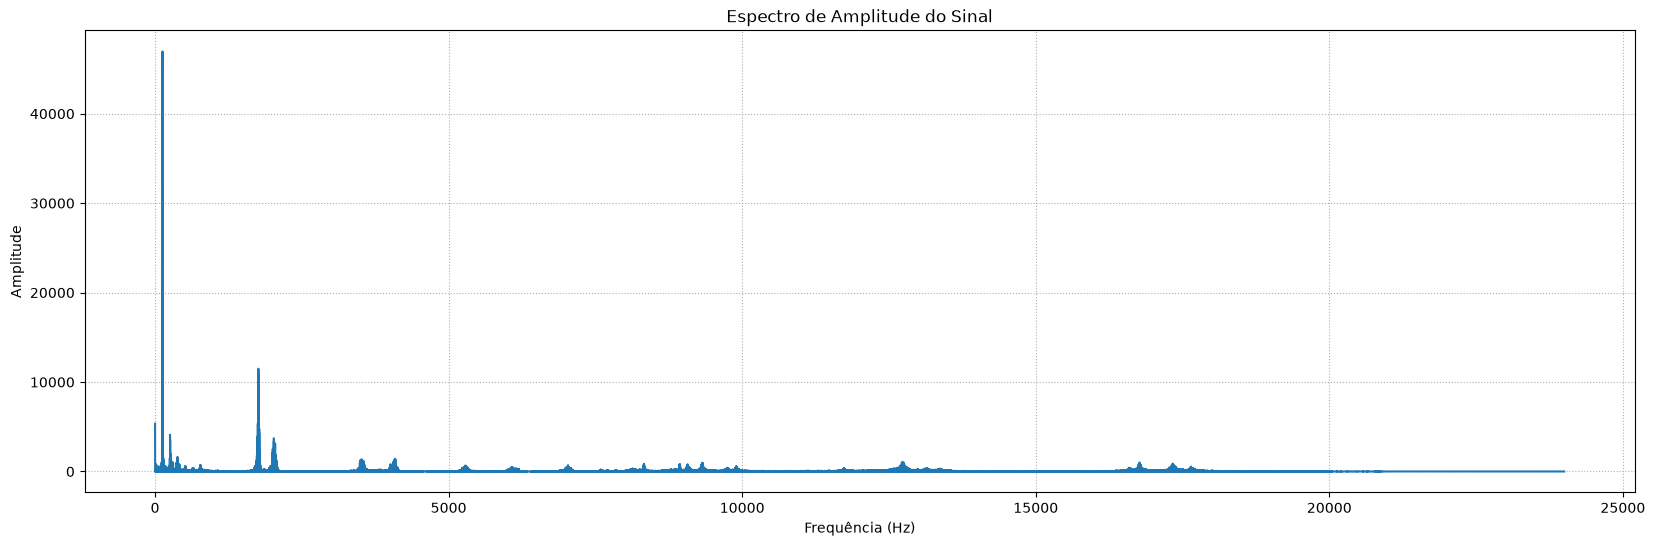

In [39]:
X = np.fft.fft(x)

Xa = abs(X)
f  = n*fs/N

plt.figure(figsize=(20,6))
plt.plot(f[:N//2] , Xa[:N//2])
plt.grid(True, linestyle=':')
ylabel('Amplitude')
xlabel('Frequência (Hz)')
plt.title('Espectro de Amplitude do Sinal')
plt.show()

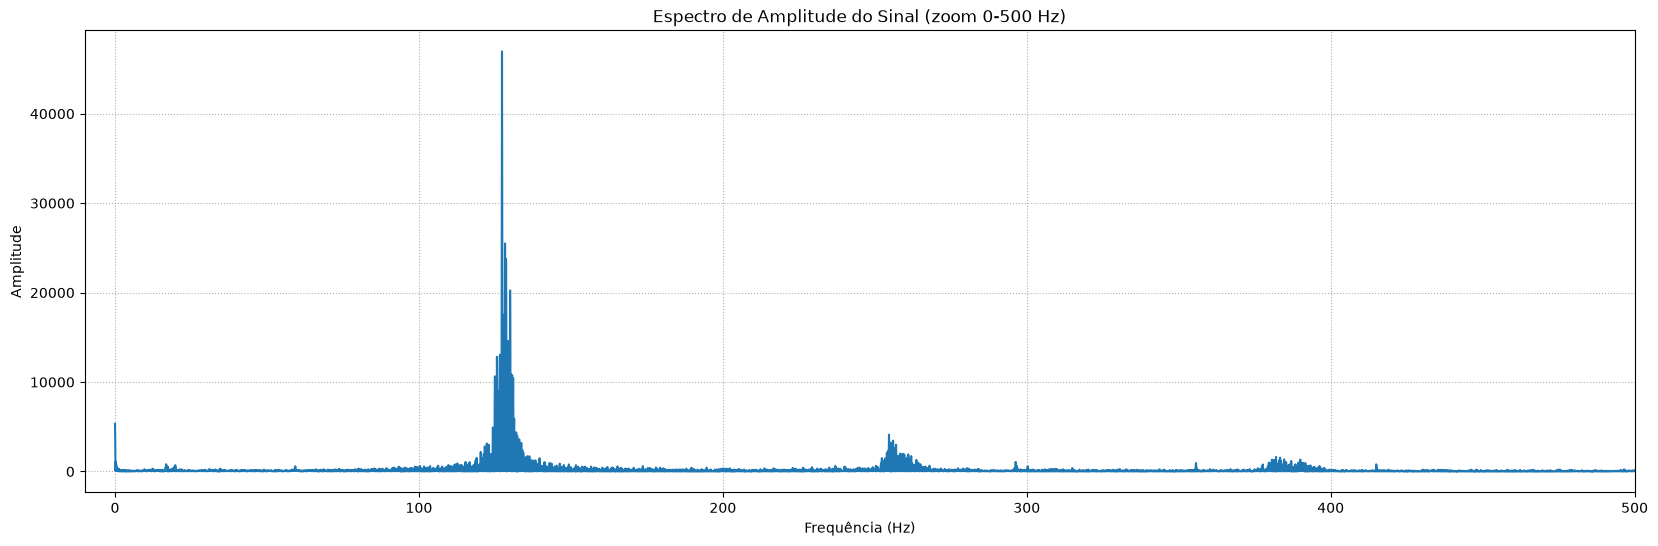

In [57]:
plt.figure(figsize=(20,6))
plt.plot(f[:N//2] , Xa[:N//2])
plt.grid(True, linestyle=':')
ylabel('Amplitude')
xlabel('Frequência (Hz)')
plt.xlim(-10,500)
plt.title('Espectro de Amplitude do Sinal (zoom 0-500 Hz)')
plt.show()

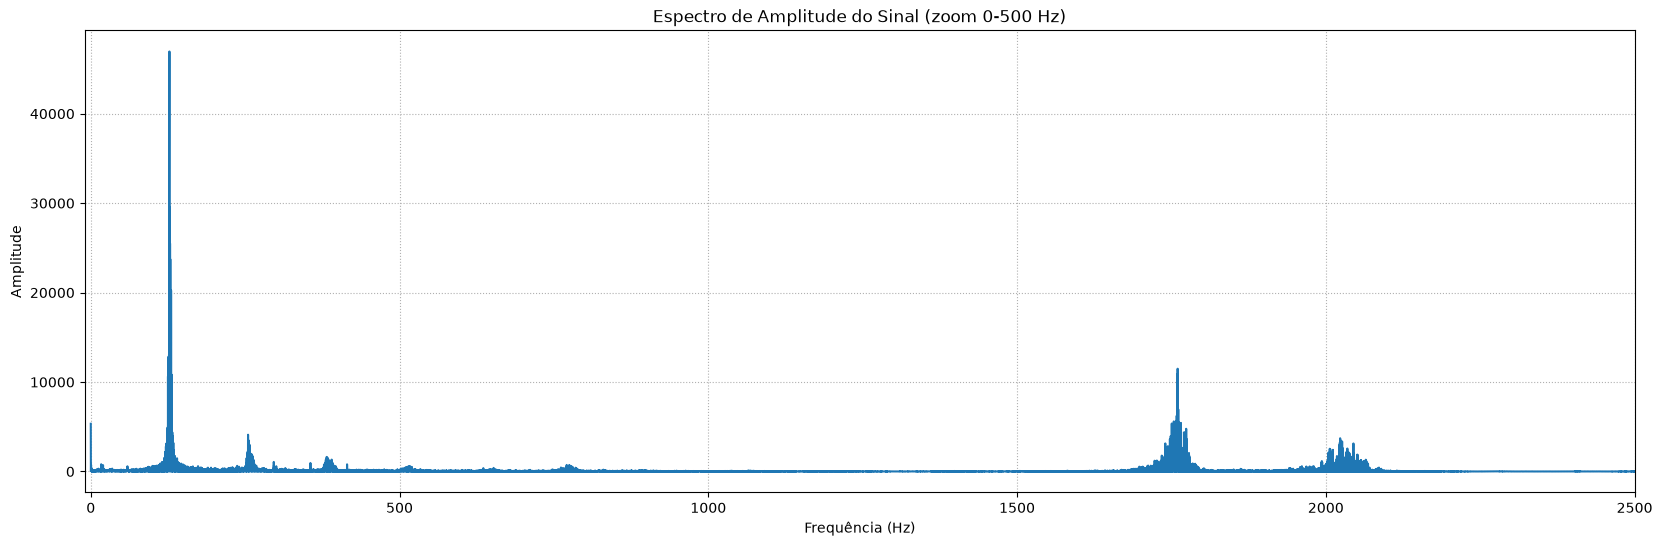

In [ ]:
plt.figure(figsize=(20,6))
plt.plot(f[:N//2] , Xa[:N//2])
plt.grid(True, linestyle=':')
ylabel('Amplitude')
xlabel('Frequência (Hz)')
plt.xlim(-10,2500)
plt.title('Espectro de Amplitude do Sinal (zoom 0-2500 Hz)')
plt.show()

Ao observar o espectro de amplitude do sinal completo, verifica-se que a maior parte da energia está concentradas em baixas frequências, em aproximadamente 130 Hz (e suas harmônicas). Também há duas componente que se destacam em aproximadamente 1750 e 2000 Hz. O espectro possui vários picos (menos acentuados) distribuídos entre 2500 e 17500 Hz e não possui componentes de energia significativas em bandas acima de 18 kHz.

## Exercício 4: Ilustre e analize (descreva) o espectograma do sinal

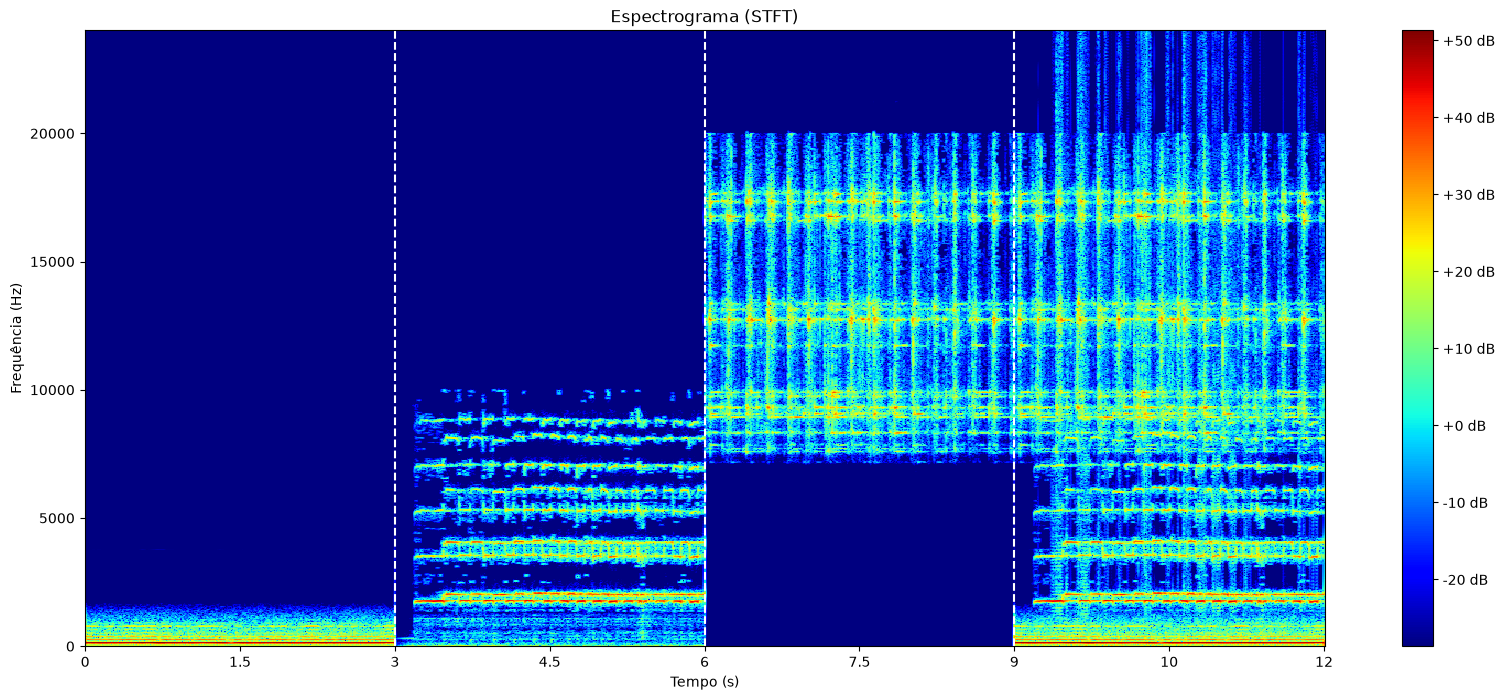

In [61]:
X_stft = np.abs(librosa.stft(x))
plt.figure(figsize=(20,8))
specshow(librosa.amplitude_to_db(X_stft),
         y_axis='linear',
         x_axis='time',
         cmap='jet',
         sr=fs)
plt.title('Espectrograma (STFT)')
plt.xlabel('Tempo (s)')
plt.ylabel('Frequência (Hz)')
plt.colorbar(format='%+2.0f dB')
for ti in [3, 6, 9]:
    plt.axvline(ti, color='white', linestyle='--')
plt.show()

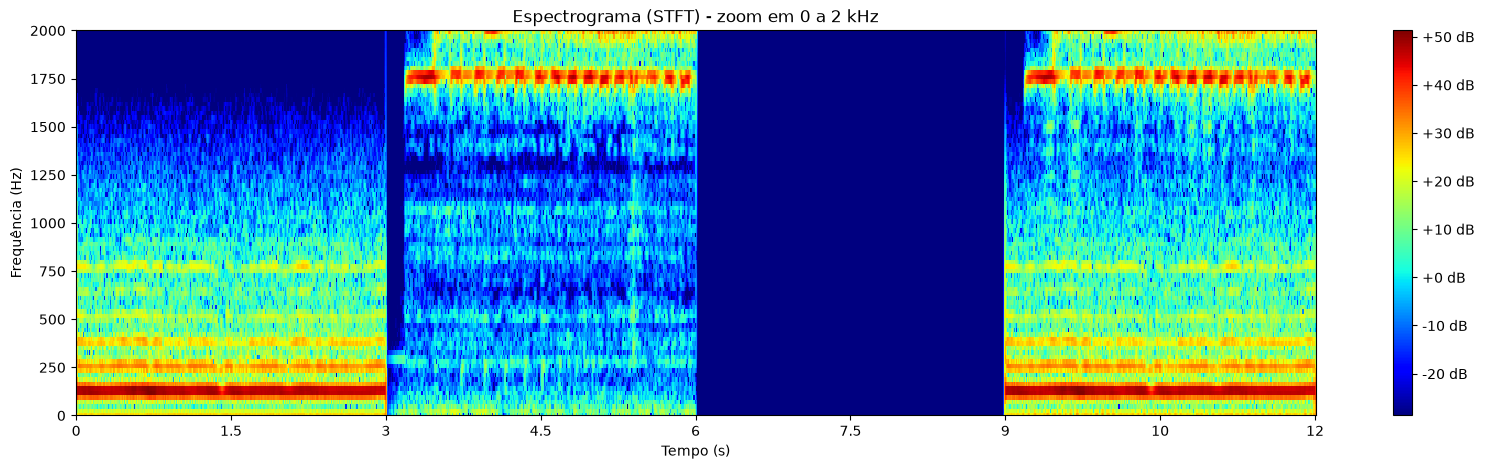

In [64]:
plt.figure(figsize=(20,5))
specshow(librosa.amplitude_to_db(X_stft), y_axis='linear', x_axis='time', cmap='jet', sr=fs)
plt.ylim(0, 2000)
plt.title('Espectrograma (STFT) - zoom em 0 a 2 kHz')
plt.xlabel('Tempo (s)')
plt.ylabel('Frequência (Hz)')
plt.colorbar(format='%+2.0f dB')
plt.show()

O espectrograma permite observar simultaneamente as componentes de frequência e sua evolução ao longo do tempo. Com isso, cada um dos trechos fica visivelmente separado (em 3, 6 e 9 segundos). 

No primeiro segmento, a vogal "u" concentra toda a energia em componentes de baixa frequência, especialmente em aproximadamente 130 Hz, como apresentado no espectro de magnitude. 

Já o segundo segmento é o responsável pelas componentes de 1750 e 2000 Hz observadas anteriormente, com componentes de energia de até 10 kHz, e o terceiro segmento (chaves) é basicamente composto por componentes de alta frequência (8-20 kHz). 

Interessante também observar que no último segmento, que é justamente a soma dos 3 anteriores, o espectrograma resultante é bem similar ao resultado da soma dos espectrogramas individuais de cada segmento. Além disso, é possível observar que surgiram novas componentes de frequência maiores que 20 kHz que não havia nos 3 segmentos anteriores. Isso possivelmente é resultado da saturação comentada anteriormente, na qual o corte abrupto nos limiares da forma de onda (-1 e 1) gera artefatos de alta frequência no espectrograma.